# Approximating a Function with a Dense Network

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lee2716/Dive_into_Deep_Learning_Code_Implementation/blob/main/myfirstNN.ipynb)

This is a very simple example of neural network. Its purpose is to approximate an unknown single valued function using a dense deep network.
The user is invited to play with it, modifying:
1. the hidden function
2. the number of layers and neurons per layer
3. activation functions, number of epochs, and so on.

In [1]:
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model
import numpy as np
import matplotlib.pyplot as plt

"myhiddenfunction" is the definition of the function you want to approximate by means of a neural network (NN). The definition is hidden to the NN, who can only access it as a blackbox, to get training samples.
This is implemented by means of a generator (a special kind of function), taking in input a number (batchsize) and returning a pair of input output vectors of length batchsize. Each input is a random number in the interval **[-pi,pi]** and the output is computed by means of myhiddenfunction.

In [2]:
def myhiddenfunction(x):
  #define your favourite function
  #output in range 0-1 if last activation is a sigmoid!
  return (np.sin(x)**2 + np.cos(x)/3 + 1)/3

def generator(batchsize):
    while True:
      inputs = np.random.uniform(low=-np.pi,high=np.pi,size=batchsize)
      outputs = np.zeros(batchsize)
      for i in range(0,batchsize):
          outputs[i] = myhiddenfunction(inputs[i])
      yield (inputs.reshape(-1, 1), outputs)  # shape (batchsize, 1) to match Input(shape=(1,))

If you want to see an example of a generated batch, you need to invoke next on the generator

In [3]:
print(next(generator(5)))

(array([[ 0.67434747],
       [-0.4165924 ],
       [-1.48054282],
       [-0.05945975],
       [-1.62190925]]), array([0.55007719, 0.48952109, 0.67397336, 0.44542519, 0.66011984]))


Now we define the network. The function we want to approximate is single valued, so the network will have a single input and a single output, and its (dense) structure is completely defined by a
list specifying the number of neurons per layer

## Why `Input(shape=(1,))`?

We set `Input(shape=(1,))` because the input data has only **one feature (one-dimensional input)**.

### Why `shape=(1,)`?
- In machine learning, the **shape of the input layer** should match the **dimensionality of the input data**.
- `shape=(1,)` means each input sample consists of **a single numerical value**.

# How Does the Dense Layer Work?

The `Dense` layer is a **fully connected layer** in a neural network, meaning every neuron in the layer is connected to all neurons in the previous layer.

## **Mathematical Representation**
Each neuron in a `Dense` layer computes the following function:

$$
y = activation(W \cdot x + b)
$$

Where:
- \( x \) = Input vector (features from the previous layer).
- \( W \) = Weight matrix (learned parameters).
- \( b \) = Bias term (if `use_bias=True`).
- `activation` = Activation function applied to the output.
- \( y \) = Final output of the neuron.

## **Step-by-Step Working**

### **1. Receives Input**
- Each neuron gets input values from all neurons in the previous layer.
- If the input has **N features**, the weight matrix \( W \) will have **N weights per neuron**.

### **2. Linear Transformation**
- The input is multiplied by the weight matrix:

  $$
  W \cdot x
  $$

- A bias term \( b \) is added:

  $$
  z = W \cdot x + b
  $$

### **3. Apply Activation Function**
- The result \( z \) is passed through an activation function:

  $$
  y = activation(z)
  $$

- **Common activation functions**:
  - **ReLU (`relu`)**: Helps with non-linearity.
  - **Sigmoid (`sigmoid`)**: Maps output between 0 and 1.
  - **Softmax (`softmax`)**: Used for multi-class classification.

### **4. Pass Output to the Next Layer**
- The computed values become inputs to the next layer.

## **Key Takeaways**
✅ Each neuron in a `Dense` layer receives input from **all neurons in the previous layer**.  
✅ The layer **learns weights and biases** through training.  
✅ The activation function introduces **non-linearity** to the network.  
✅ The `Dense` layer is fundamental in **fully connected neural networks (FCNNs)**.  




In [4]:
input_layer = Input(shape=(1,))
x = Dense(20, activation='relu')(input_layer)
x = Dense(30, activation='relu')(x)
x = Dense(20, activation='relu')(x)
output_layer = Dense(1,activation='relu')(x)

mymodel = Model(input_layer,output_layer)

Here is an alternative, more modular definition of the same network.

# 🔍 Key Differences: Loop vs. Manual Implementation  

| Feature | **Loop Implementation** | **Manual Implementation** |
|---------|-------------------------|---------------------------|
| **Hidden Layers Definition** | Uses a **loop** to create layers dynamically. | Manually defines each `Dense` layer one by one. |
| **Scalability** | **Easier to modify** (just change `inner_layers_dims`). | **Less flexible** (requires adding layers manually). |
| **Readability** | Slightly **less readable** due to the loop. | More **explicit and easier to read**. |
| **Functionality** | Both create the same network with **(20, 30, 20) hidden layers**. | Exactly the same as the first code but written manually. |

## 🔢 Model Architecture (Same for Both)  

| Layer | Type  | Neurons | Activation |
|--------|--------|----------|--------------|
| Input | Input Layer | 1 | - |
| Hidden 1 | Dense | 20 | ReLU |
| Hidden 2 | Dense | 30 | ReLU |
| Hidden 3 | Dense | 20 | ReLU |
| Output | Dense | 1 | ReLU |

## 🎯 Which One Should You Use?  

✅ **Use the first (loop version) if:**  
- You want to **easily modify the number of hidden layers**.  
- You're **experimenting** with different architectures dynamically.  

✅ **Use the second (manual version) if:**  
- The architecture is **fixed** and won’t change.  
- You want **better readability** for debugging.  

---

### 🛠 **Final Verdict**  
**Both implementations result in the exact same neural network!**  
The first one is more **scalable**, while the second is more **explicit**. 🚀  


In [5]:
# size of hidden layers (one for each of them)
inner_layers_dims = [20,30,20]

input_layer = Input(shape=(1,))
x = input_layer
for i in range(0,len(inner_layers_dims)):
  x = Dense(inner_layers_dims[i], activation='relu')(x)
output_layer = Dense(1, activation='relu')(x)

mymodel1 = Model(input_layer,output_layer)

We can now have a look at the model we just generated:

In [6]:
mymodel.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 1)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 20)             │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 30)             │           630 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 20)             │           620 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            21 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,311 (5.12 KB)

 Trainable params: 1,311 (5.12 KB)

 Non-trainable params: 0 (0.00 B)

Try to be sure you correctly understand the number of learning parameters for each layer.
For a dense layer with n input neurons and m output neurons, your have nxm weights + m biases.
For instance, for a 20-to-30 layer, we have 20x30+30 = 630 parameters.

We are finally ready to compile our model and train it.
As loss function we use mean square error (mse).
The "optimizer" is the technique used to tune the learning rate during backpropagation: you may ignore it for the moment.

**model.compiler:configure parameters before training**

In [7]:
mymodel.compile(optimizer='adam', loss='mse')

# 📌 How It Works  

## 1️⃣ `batchsize = 64`
- Defines the **batch size**: The number of samples processed **per batch**.  
- The generator will produce **batches of 64 samples** at a time.  

---

## 2️⃣ `generator(batchsize)`
- Calls the `generator` function, which **dynamically yields batches** of training data.  
- Each batch contains **`batchsize=64`** samples.  
- Useful when dealing with **large datasets** that **don’t fit into memory**.  

---

## 3️⃣ `steps_per_epoch=1000`
- Defines how many **batches** are processed in **one epoch**.  
- Since each batch contains **64 samples**, the model processes:  
  $$
1000 \times 64 = 64,000 \text{ samples per epoch}
$$
- Helps in controlling **how often** the weights are updated.  

---

## 4️⃣ `epochs=10`
- Defines how many **full training cycles** the model will go through.  
- Since `steps_per_epoch=1000`, the total number of updates is:  
  $$
1000 \times 10 = 10,000 \text{ weight updates}
$$
- The model will **train for 10 complete passes** over the dataset.  

---

## 🎯 **Key Takeaways**
✅ `fit()` is used when training with a **data generator**.  
✅ `batchsize=64` defines how many samples are processed **at once**.  
✅ `steps_per_epoch=1000` means the model processes **1000 batches per epoch**.  
✅ `epochs=10` ensures the model completes **10 full training cycles**.  
✅ Useful for **memory-efficient training** and **real-time data augmentation**.  


In [8]:
batchsize = 64

mymodel.fit(generator(batchsize), steps_per_epoch=1000, epochs=10, verbose=2)

Epoch 1/10


1000/1000 - 3s - 3ms/step - loss: 0.0067


Epoch 2/10


1000/1000 - 2s - 2ms/step - loss: 1.4313e-06


Epoch 3/10


...

1000/1000 - 2s - 2ms/step - loss: 1.2246e-05


Epoch 9/10


1000/1000 - 2s - 2ms/step - loss: 1.9148e-06


Epoch 10/10


1000/1000 - 2s - 2ms/step - loss: 4.6469e-06


If everything is working correctly, the loss should decrease during training.  
If it doesn't, it means that, for some reason, the network is not learning.

We are finally ready to check the result of the approximation. We plot the hidden function in red,
and the approximation computed by the network in blue.

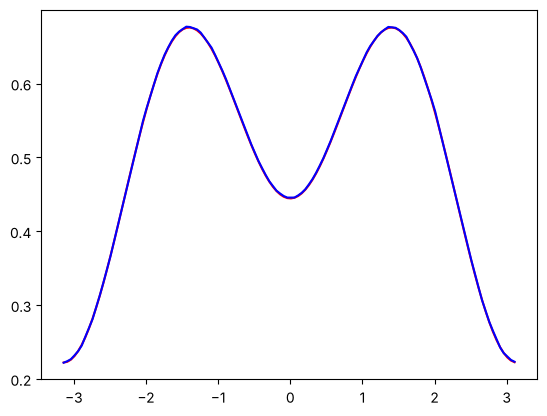

In [9]:
x = np.arange(-np.pi,np.pi,0.05)
y = [myhiddenfunction(a) for a in x]
z = [z[0] for z in mymodel.predict(x.reshape(-1, 1), verbose=0)]
plt.plot(x,y,'r',x,z,'b')
plt.show()


Now is your turn. Modify:

1. the definition of the hidden function
2. the number of layers/neurons per layer; you just have to change inner_layers_dims in the modular definition above (and use `mymodel1`).

Have fun.